In [0]:
%sql

SELECT
    dc.customer_state AS estado,
    ROUND(AVG(fdm.total_delivery_days), 2) AS tempo_medio_entrega_dias,
    COUNT(*) AS pedidos_entregues
FROM olist_dw.dw.fact_delivery_metrics fdm
INNER JOIN olist_dw.dw.dim_customer dc
    ON fdm.customer_sk = dc.customer_sk
WHERE fdm.order_status = 'delivered'
  AND fdm.order_delivered_customer_date IS NOT NULL
  AND fdm.total_delivery_days IS NOT NULL
GROUP BY dc.customer_state
ORDER BY tempo_medio_entrega_dias DESC;


estado,tempo_medio_entrega_dias,pedidos_entregues
RR,29.41,41
AP,27.12,67
AM,26.41,145
AL,24.48,397
PA,23.76,946
MA,21.58,717
SE,21.42,335
CE,21.25,1279
AC,21.11,80
PB,20.38,517


In [0]:
%sql

SELECT
    COUNT(*) AS total_pedidos_entregues,
    SUM(
        CASE
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
            THEN 1
            ELSE 0
        END
    ) AS pedidos_com_atraso,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN order_delivered_customer_date >
                     order_estimated_delivery_date
                THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS percentual_atraso
FROM olist_dw.dw.fact_delivery_metrics
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL;


total_pedidos_entregues,pedidos_com_atraso,percentual_atraso
96470,7826,8.11


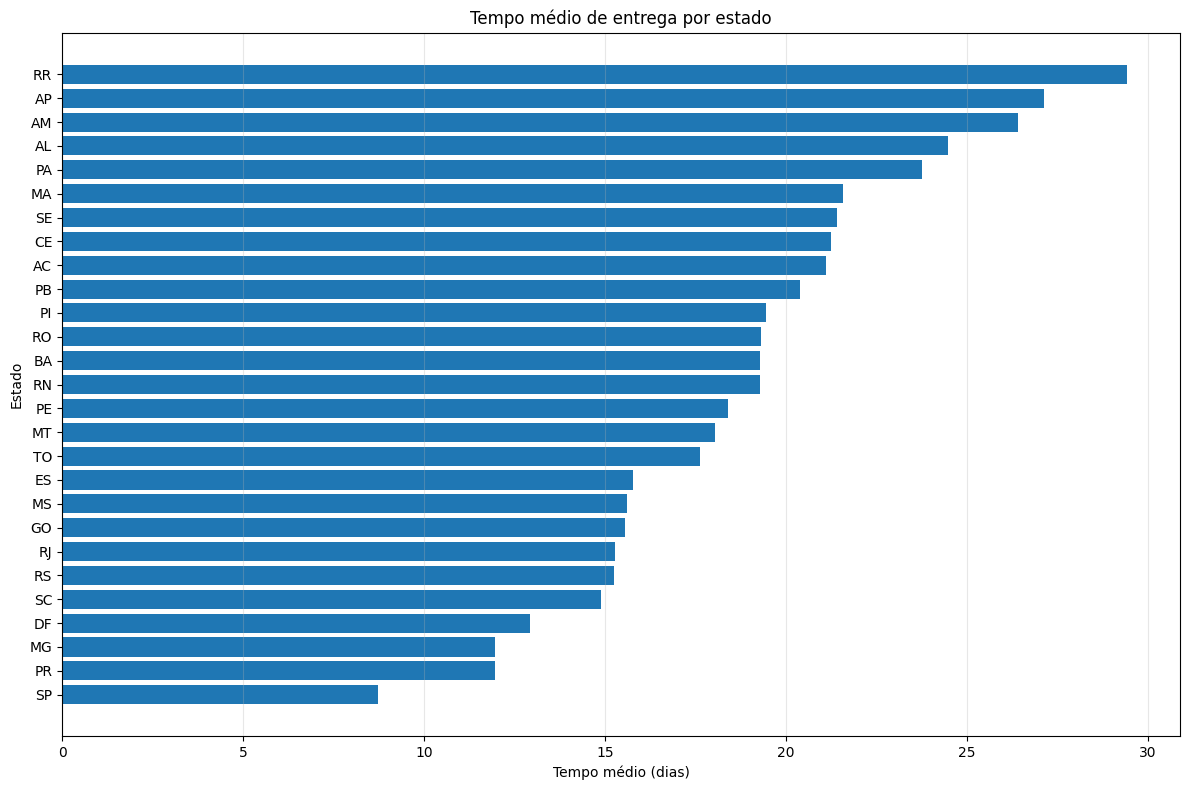

In [0]:

import matplotlib.pyplot as plt

df_states = spark.sql("""
    SELECT
        dc.customer_state AS estado,
        AVG(fdm.total_delivery_days) AS tempo_medio_entrega_dias,
        COUNT(*) AS pedidos_entregues
    FROM olist_dw.dw.fact_delivery_metrics fdm
    INNER JOIN olist_dw.dw.dim_customer dc
        ON fdm.customer_sk = dc.customer_sk
    WHERE fdm.order_status = 'delivered'
      AND fdm.order_delivered_customer_date IS NOT NULL
      AND fdm.total_delivery_days IS NOT NULL
    GROUP BY dc.customer_state
    ORDER BY tempo_medio_entrega_dias
""").toPandas()

plt.figure(figsize=(12, 8))
plt.barh(
    df_states["estado"],
    df_states["tempo_medio_entrega_dias"]
)

plt.title("Tempo médio de entrega por estado")
plt.xlabel("Tempo médio (dias)")
plt.ylabel("Estado")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/tempo_medio_estado.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


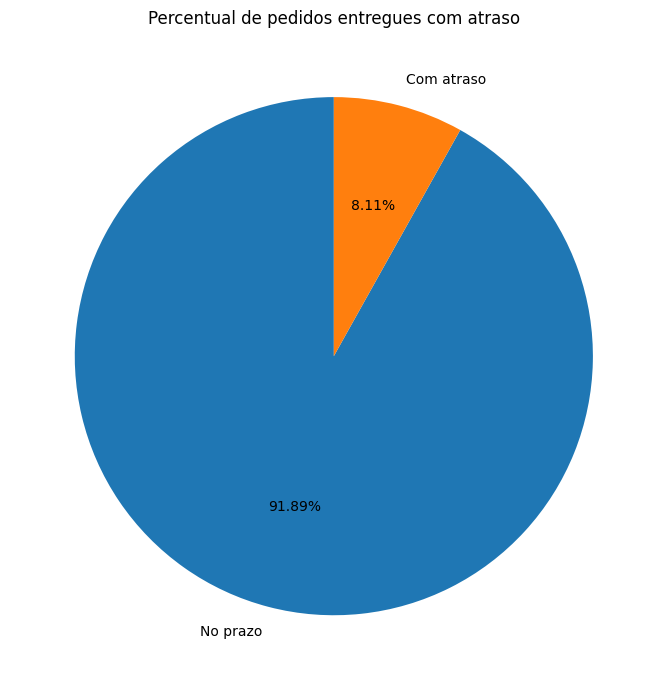

In [0]:

import matplotlib.pyplot as plt

df_delivery = spark.sql("""
    SELECT
        CASE
            WHEN order_delivered_customer_date >
                 order_estimated_delivery_date
            THEN 'Com atraso'
            ELSE 'No prazo'
        END AS status_entrega,
        COUNT(*) AS quantidade
    FROM olist_dw.dw.fact_delivery_metrics
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
    GROUP BY 1
""").toPandas()

plt.figure(figsize=(8, 7))
plt.pie(
    df_delivery["quantidade"],
    labels=df_delivery["status_entrega"],
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Percentual de pedidos entregues com atraso")
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/percentual_atraso.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
